In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

rating=pd.read_csv("Data/ratings.csv")
movie=pd.read_csv("Data/movies.csv")
print(rating)
print(movie)


        userId  movieId  rating   timestamp
0            1        1     4.0   964982703
1            1        3     4.0   964981247
2            1        6     4.0   964982224
3            1       47     5.0   964983815
4            1       50     5.0   964982931
...        ...      ...     ...         ...
100831     610   166534     4.0  1493848402
100832     610   168248     5.0  1493850091
100833     610   168250     5.0  1494273047
100834     610   168252     5.0  1493846352
100835     610   170875     3.0  1493846415

[100836 rows x 4 columns]
      movieId                                      title  \
0           1                           Toy Story (1995)   
1           2                             Jumanji (1995)   
2           3                    Grumpier Old Men (1995)   
3           4                   Waiting to Exhale (1995)   
4           5         Father of the Bride Part II (1995)   
...       ...                                        ...   
9737   193581  Black Butl

In [21]:
#database statistics
nusers=rating.userId.nunique()
nmovies=rating.movieId.nunique()  # only movies that have at least one rating
nrating=len(rating.rating)
Sparsity=(1-(nrating/(nusers*nmovies)))*100
print(nusers,nmovies,nrating,Sparsity)

610 9724 100836 98.30003169443864


In [34]:
#Make a User-Item Matrix
rating_matrix = rating.pivot(
    index="userId",
    columns="movieId",
    values="rating"
)

rating_matrix

movieId,1,2,3,4,5,6,7,8,9,10,...,193565,193567,193571,193573,193579,193581,193583,193585,193587,193609
userId,,,,,,,,,,,,,,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
606,2.5,NaN,NaN,NaN,NaN,NaN,2.5,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
607,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
608,2.5,2.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,4.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [50]:
#rating ditribution
rating_dist=rating.rating.value_counts()
print(rating_dist)
#rating per user
user_dis=rating.userId.value_counts()
print(user_dis)

rating
4.0    26818
3.0    20047
5.0    13211
3.5    13136
4.5     8551
2.0     7551
2.5     5550
1.0     2811
1.5     1791
0.5     1370
Name: count, dtype: int64
userId
414    2698
599    2478
474    2108
448    1864
274    1346
       ... 
431      20
442      20
569      20
576      20
595      20
Name: count, Length: 610, dtype: int64


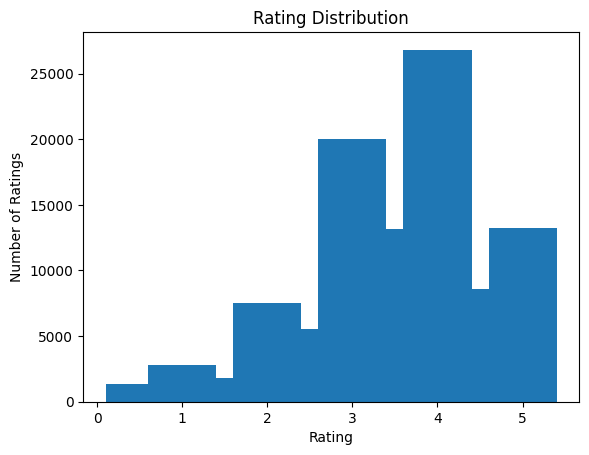

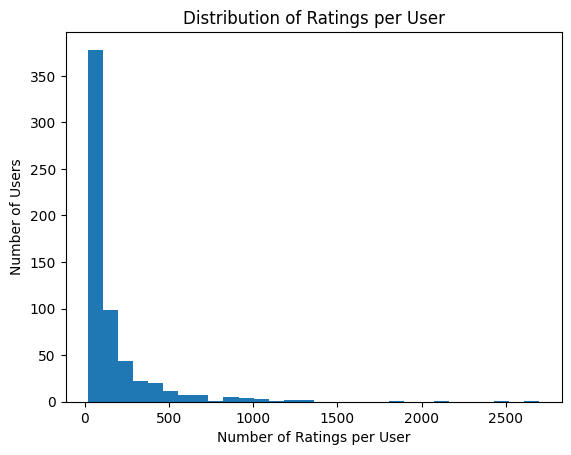

In [51]:
#bar_chart per rating (get some help from ai)
plt.bar(rating_dist.index, rating_dist.values)
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.title("Rating Distribution")
plt.show()
#bar_chart per user
plt.hist(user_dis.values, bins=30)
plt.xlabel("Number of Ratings per User")
plt.ylabel("Number of Users")
plt.title("Distribution of Ratings per User")
plt.show()

In [52]:
def get_co_rated(matrix, a, b, axis):
    # a and b are real IDs (userId or movieId), not positions
    if axis == "index":
        first = matrix.loc[a]
        second = matrix.loc[b]
    elif axis == "columns":
        first = matrix.loc[:, a]
        second = matrix.loc[:, b]
    else:
        raise ValueError('axis must be "index" or "columns"')

    # keep only the entries where both have a rating
    mask = ~np.isnan(first) & ~np.isnan(second)
    return first[mask].values, second[mask].values


In [53]:
# Euclidean similarity
def euclidean_similarity(vec1, vec2):
    if len(vec1) < 2:
        return None
    d = np.sqrt(np.sum((vec1 - vec2)**2))
    similarity = 1/(1+d)
    return similarity

# Cosine similarity
def cosine_similarity(vec1, vec2):
    if len(vec1) < 2:
        return None
    denominator = np.linalg.norm(vec1) * np.linalg.norm(vec2) # ai help with linalg.norm

    if denominator == 0:
        return None

    similarity = np.dot(vec1, vec2) / denominator

    return similarity

# Pearson similarity
def pearson_similarity(vec1, vec2):
    if len(vec1) < 2:
        return None
    # Pearson is the cosine similarity of the mean-centered vectors
    vec1_centered = vec1 - np.mean(vec1)
    vec2_centered = vec2 - np.mean(vec2)
    return cosine_similarity(vec1_centered, vec2_centered)


In [54]:
# sanity check against the worked example in Section 3.2
A = np.array([5, 4, 5, 3])
B = np.array([3, 2, 3, 1])
print("Euclidean distance:  ", np.sqrt(np.sum((A - B)**2)))              # 4.0
print("Euclidean similarity:", euclidean_similarity(A, B))               # 0.2 (= 1/(1+4))
print("Cosine:              ", round(cosine_similarity(A, B), 3))        # 0.987
print("Pearson:             ", round(pearson_similarity(A, B), 3))       # 1.0


Euclidean distance:   4.0
Euclidean similarity: 0.2
Cosine:               0.987
Pearson:              1.0


In [55]:
# get_co_rated on a toy matrix whose ids are NOT 0,1,2... (like MovieLens)
toy = pd.DataFrame([[5, 4, 5, 3], [3, 2, 3, 1]], index=[10, 20], columns=[101, 102, 103, 104])
v1, v2 = get_co_rated(toy, 10, 20, "index")
print(v1, v2)                                             # [5 4 5 3] [3 2 3 1]

# get_co_rated on the real matrix: users 1 and 2 share 2 movies, users 1 and 5 share 13
v1, v2 = get_co_rated(rating_matrix, 1, 2, "index")
print(len(v1), v1, v2)
v1, v2 = get_co_rated(rating_matrix, 1, 5, "index")
print(len(v1))

# the three metrics on a real pair of users (fewer than 2 co-rated entries gives None)
print(euclidean_similarity(v1, v2), cosine_similarity(v1, v2), pearson_similarity(v1, v2))


[5 4 5 3] [3 2 3 1]
2 [5. 5.] [4. 4.]
13
0.21089672205953397 0.9707699301444195 0.2687490263457713


In [63]:
def find_k_nearest_users(matrix, target_user, k, similarity_fn):
    scores = []
    for other_user in matrix.index:
        if other_user == target_user:
            continue  # a user is not their own neighbor

        vec1, vec2 = get_co_rated(matrix, target_user, other_user, axis="index")
        if len(vec1) < 2:
            continue  # fewer than 2 co-rated items: similarity is undefined, skip

        score = similarity_fn(vec1, vec2)
        if score is None:
            continue  # the metric could not be computed for this pair

        scores.append((other_user, score))

    scores.sort(key=lambda pair: pair[1], reverse=True)
    return scores[:k]


In [64]:
# the 5 nearest users to user 1 with each similarity metric: (user id, score)
for name, fn in [("euclidean", euclidean_similarity), ("cosine", cosine_similarity), ("pearson", pearson_similarity)]:
    nearest = find_k_nearest_users(rating_matrix, 1, 5, fn)
    print(name, [(int(user), round(float(score), 3)) for user, score in nearest])


euclidean [(77, 1.0), (278, 0.667), (472, 0.667), (511, 0.667), (550, 0.667)]
cosine [(77, 1.0), (12, 1.0), (2, 1.0), (511, 0.999), (278, 0.999)]
pearson [(146, 1.0), (550, 1.0), (106, 1.0), (333, 1.0), (598, 1.0)]


In [65]:
def predict_rating_user_based(matrix, target_user, target_item, k, similarity_fn):
    if target_user not in matrix.index or target_item not in matrix.columns:
        return None  # unknown user or item: nothing to predict from

    neighbors = find_k_nearest_users(matrix, target_user, k, similarity_fn)

    numerator = 0.0
    denominator = 0.0
    for neighbor, similarity in neighbors:
        neighbor_rating = matrix.loc[neighbor, target_item]
        if np.isnan(neighbor_rating):
            continue  # this neighbor did not rate the target item
        numerator += similarity * neighbor_rating
        denominator += abs(similarity)

    if denominator == 0:
        return None  # none of the k neighbors rated the item
    return numerator / denominator


In [66]:
# predicted rating of user 1 for movie 318 with k=20 and each similarity metric
for name, fn in [("euclidean", euclidean_similarity), ("cosine", cosine_similarity), ("pearson", pearson_similarity)]:
    print(name, predict_rating_user_based(rating_matrix, 1, 318, 20, fn))


euclidean 4.7918967920028095
cosine 4.449845252882381
pearson 4.623973837700031


In [67]:
def find_k_nearest_items(matrix, target_item, k, similarity_fn):
    scores = []
    for other_item in matrix.columns:
        if other_item == target_item:
            continue  # an item is not its own neighbor

        vec1, vec2 = get_co_rated(matrix, target_item, other_item, axis="columns")
        if len(vec1) < 2:
            continue  # fewer than 2 users rated both items: similarity is undefined, skip

        score = similarity_fn(vec1, vec2)
        if score is None:
            continue  # the metric could not be computed for this pair

        scores.append((other_item, score))

    scores.sort(key=lambda pair: pair[1], reverse=True)
    return scores[:k]


In [61]:
# the 5 nearest movies to movie 318 with each similarity metric: (movie id, score)
for name, fn in [("euclidean", euclidean_similarity), ("cosine", cosine_similarity), ("pearson", pearson_similarity)]:
    nearest = find_k_nearest_items(rating_matrix, 318, 5, fn)
    print(name, [(int(item), round(float(score), 3)) for item, score in nearest])


euclidean [(132, 1.0), (715, 1.0), (1150, 1.0), (3372, 1.0), (3422, 1.0)]
cosine [(841, 1.0), (3813, 1.0), (4956, 1.0), (6184, 1.0), (8526, 1.0)]
pearson [(270, 1.0), (725, 1.0), (1971, 1.0), (1992, 1.0), (1995, 1.0)]


In [68]:
def predict_rating_item_based(matrix, target_user, target_item, k, similarity_fn):
    if target_user not in matrix.index or target_item not in matrix.columns:
        return None  # unknown user or item: nothing to predict from

    neighbors = find_k_nearest_items(matrix, target_item, k, similarity_fn)

    numerator = 0.0
    denominator = 0.0
    for neighbor, similarity in neighbors:
        neighbor_rating = matrix.loc[target_user, neighbor]
        if np.isnan(neighbor_rating):
            continue  # the target user did not rate this neighbor item
        numerator += similarity * neighbor_rating
        denominator += abs(similarity)

    if denominator == 0:
        return None  # the user rated none of the k neighbor items
    return numerator / denominator


In [69]:
# predicted rating of user 414 for movie 356 (real rating 5.0) with k=20, item-based, each similarity metric
for name, fn in [("euclidean", euclidean_similarity), ("cosine", cosine_similarity), ("pearson", pearson_similarity)]:
    print(name, predict_rating_item_based(rating_matrix, 414, 356, 20, fn))


euclidean 5.0
cosine 3.0
pearson 3.4999999999999996


**Part D: what was reused from Part C and what changed**

`find_k_nearest_items` and `predict_rating_item_based` follow exactly the same logic as `find_k_nearest_users` and `predict_rating_user_based`, and both rely on the same `get_co_rated` and the same three similarity functions. Only the direction changes. In `find_k_nearest_items` we loop over the columns (movies) instead of the rows (users) and call `get_co_rated` with `axis="columns"`, so two movies are compared on the users who rated both. In `predict_rating_item_based` the neighbors are movies similar to the target movie, and the weighted average uses the target user's own ratings of those neighbor movies (`matrix.loc[target_user, neighbor]`) instead of the neighbors' ratings of the target movie.


In [81]:
#  split + evaluate (vectorized)
# AI-ASSISTED START
def train_test_split_ratings(ratings_df, test_fraction=0.2, seed=42):
    test_df = ratings_df.groupby("userId").sample(frac=test_fraction, random_state=seed)
    train_df = ratings_df.drop(test_df.index)
    return train_df, test_df
 
def similarity_rows(Rz, Mf, rows, metric, min_common=2):
    Rb, Mb = Rz[rows], Mf[rows]
    n    = Mb @ Mf.T
    dot  = Rb @ Rz.T
    sq_i = (Rb**2) @ Mf.T
    sq_j = Mb @ (Rz**2).T
    with np.errstate(divide="ignore", invalid="ignore"):
        if metric == "euclidean":
            sim = 1/(1+np.sqrt(np.maximum(sq_i + sq_j - 2*dot, 0)))
        elif metric == "cosine":
            den = np.sqrt(sq_i*sq_j)
            sim = np.where(den > 0, dot/den, np.nan)
        elif metric == "pearson":
            S_i, S_j = Rb @ Mf.T, Mb @ Rz.T
            cov   = dot - S_i*S_j/n
            var_i = sq_i - S_i**2/n
            var_j = sq_j - S_j**2/n
            den = np.sqrt(np.maximum(var_i, 0)*np.maximum(var_j, 0))
            sim = np.where(den > 1e-9, cov/den, np.nan)
    sim[n < min_common] = np.nan
    sim[np.arange(len(rows)), rows] = np.nan
    return sim
 
def top_neighbors(X, metric, k_max=50, block=250, min_common=2):
    M  = ~np.isnan(X)
    Mf = M.astype(np.float64)
    Rz = np.where(M, X, 0.0)
    N  = X.shape[0]
    top_idx = np.zeros((N, k_max), dtype=np.int64)
    top_sim = np.full((N, k_max), np.nan)
    for start in range(0, N, block):
        rows = np.arange(start, min(start+block, N))
        sim = similarity_rows(Rz, Mf, rows, metric, min_common)
        filled = np.where(np.isnan(sim), -np.inf, sim)
        idx = np.argsort(-filled, axis=1, kind="stable")[:, :k_max]
        s = np.take_along_axis(filled, idx, axis=1)
        s[np.isneginf(s)] = np.nan
        top_idx[rows], top_sim[rows] = idx, s
    return top_idx, top_sim
 
SIM_NAMES = {
    euclidean_similarity: "euclidean",
    cosine_similarity: "cosine",
    pearson_similarity: "pearson",
}
_cache = {}
 
def evaluate(matrix, test_df, k, similarity_fn, method, min_common=10):
    metric = SIM_NAMES[similarity_fn]
    X = matrix.to_numpy() if method == "user" else matrix.to_numpy().T
    key = (method, metric, min_common)
    if key not in _cache:
        _cache[key] = top_neighbors(X, metric, 50, min_common=min_common)
    top_idx, top_sim = _cache[key]
 
    u_pos = matrix.index.get_indexer(test_df.userId)
    i_pos = matrix.columns.get_indexer(test_df.movieId)
    t_pos, o_pos = (u_pos, i_pos) if method == "user" else (i_pos, u_pos)
    known = (t_pos >= 0) & (o_pos >= 0)
    t, o = t_pos[known], o_pos[known]
    true = test_df.rating.to_numpy()[known]
 
    nb, w = top_idx[t, :k], top_sim[t, :k]
    r = X[nb, o[:, None]]
    ok = ~np.isnan(w) & ~np.isnan(r)
    num = np.where(ok, w*r, 0.0).sum(1)
    den = np.where(ok, np.abs(w), 0.0).sum(1)
    can = den > 0
    pred = num[can]/den[can]
    err = pred - true[can]
    rmse = np.sqrt(np.mean(err**2)); mae = np.mean(np.abs(err))
    none_frac = 1 - can.sum()/len(test_df)
    return rmse, mae, none_frac

In [ ]:
# --- AI-ASSISTED START ---
# split, build TRAIN matrix
train_df, test_df = train_test_split_ratings(rating, test_fraction=0.2, seed=42)
train_matrix = train_df.pivot(index="userId", columns="movieId", values="rating")
_cache.clear()       
print(len(train_df), len(test_df), train_df.groupby("userId").size().min())


80672 20164 16


In [ ]:
# --- AI-ASSISTED START ---
# similarities of one user / one item must match your loop version exactly
for fn in [euclidean_similarity, cosine_similarity, pearson_similarity]:
    name = SIM_NAMES[fn]
    ti, ts = top_neighbors(train_matrix.to_numpy(), name, k_max=20)
    loop = [s for _, s in find_k_nearest_users(train_matrix, 1, 20, fn)]
    print("user", name, np.allclose(loop, ts[train_matrix.index.get_loc(1)][:len(loop)]))


user euclidean True
user cosine True
user pearson True


In [ ]:
# --- AI-ASSISTED START ---
import time
t0 = time.time()
records = []
for method in ["user", "item"]:
    for fn in [euclidean_similarity, cosine_similarity, pearson_similarity]:
        for k in [5, 10, 20, 50]:
            rmse, mae, none_frac = evaluate(train_matrix, test_df, k, fn, method)
            records.append(dict(method=method, similarity=SIM_NAMES[fn], k=k,
                                RMSE=rmse, MAE=mae, frac_none=none_frac))
results = pd.DataFrame(records)
print(f"{time.time()-t0:.0f}s")
 
results.round(4)
 
 
# %% ---- cell 5: views for the analysis ----
print(results.pivot_table(index=["method", "similarity"], columns="k", values="RMSE").round(4))
print(results.pivot_table(index=["method", "similarity"], columns="k", values="frac_none").round(4))
print(results.loc[results.groupby(["method", "similarity"]).RMSE.idxmin()].round(4))   

35s
k                      5       10      20      50
method similarity                                
item   cosine      1.0997  1.0603  1.0219  0.9931
       euclidean   1.0540  1.0179  1.0016  0.9830
       pearson     1.4270  1.3854  1.3936  1.4398
user   cosine      1.1039  1.0717  1.0596  1.0309
       euclidean   1.0356  1.0414  1.0370  1.0279
       pearson     1.2775  1.2532  1.2399  1.2434
k                      5       10      20      50
method similarity                                
item   cosine      0.5449  0.4485  0.3787  0.3182
       euclidean   0.5720  0.4817  0.4091  0.3420
       pearson     0.5447  0.4430  0.3729  0.3135
user   cosine      0.7542  0.6505  0.5219  0.3313
       euclidean   0.7792  0.6862  0.5767  0.4241
       pearson     0.7395  0.6207  0.4889  0.2374
   method similarity   k    RMSE     MAE  frac_none
19   item     cosine  50  0.9931  0.7364     0.3182
15   item  euclidean  50  0.9830  0.7325     0.3420
21   item    pearson  10  1.3854  0.8832

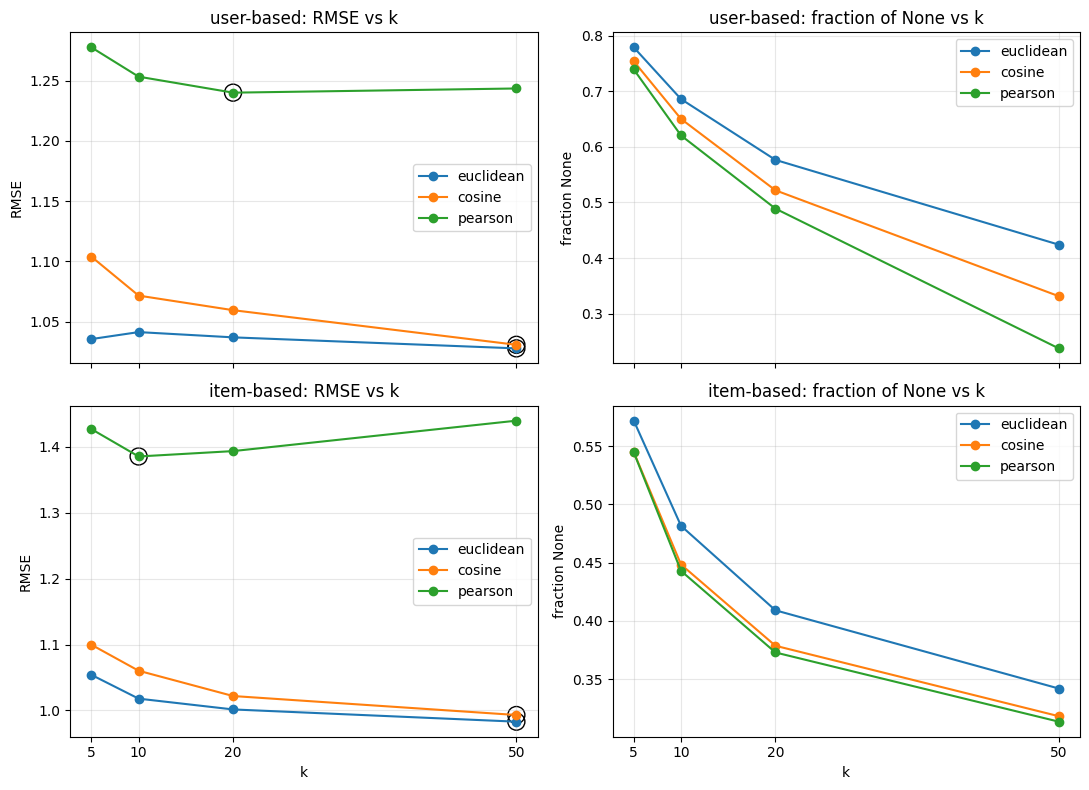

In [ ]:
# --- AI-ASSISTED START: RMSE vs k plots ---
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True)
for row, method in enumerate(["user", "item"]):
    for sim in ["euclidean", "cosine", "pearson"]:
        d = results[(results.method == method) & (results.similarity == sim)].sort_values("k")
        axes[row, 0].plot(d.k, d.RMSE, marker="o", label=sim)
        axes[row, 1].plot(d.k, d.frac_none, marker="o", label=sim)
        best = d.loc[d.RMSE.idxmin()]                       # دايرة حوالين أحسن k
        axes[row, 0].scatter(best.k, best.RMSE, s=150, facecolors="none", edgecolors="k")
    axes[row, 0].set_title(f"{method}-based: RMSE vs k")
    axes[row, 1].set_title(f"{method}-based: fraction of None vs k")
    axes[row, 0].set_ylabel("RMSE")
    axes[row, 1].set_ylabel("fraction None")
for ax in axes.ravel():
    ax.set_xticks(sorted(results.k.unique()))
    ax.grid(alpha=0.3)
    ax.legend()
for ax in axes[1]:
    ax.set_xlabel("k")
plt.tight_layout()
plt.show()

In [ ]:
# --- AI-ASSISTED START: improved CF (mean-centered, k nearest raters, shrinkage) ---
_cache2 = {}

def full_similarity(X, metric, shrink, min_common=2, block=250):
    M = ~np.isnan(X); Mf = M.astype(np.float64); Rz = np.where(M, X, 0.0)
    S = np.empty((len(X), len(X)), dtype=np.float32)
    for s in range(0, len(X), block):
        rows = np.arange(s, min(s + block, len(X)))
        n = Mf[rows] @ Mf.T
        S[rows] = similarity_rows(Rz, Mf, rows, metric, min_common) * n / (n + shrink)  # shrink: trust pairs with few co-rated items less
    return S

def evaluate_v2(matrix, test_df, k, similarity_fn, method, shrink=50, block=400):
    metric = SIM_NAMES[similarity_fn]
    X = matrix.to_numpy() if method == "user" else matrix.to_numpy().T
    if (method, metric, shrink) not in _cache2:
        _cache2.clear()
        _cache2[(method, metric, shrink)] = full_similarity(X, metric, shrink)
    S = _cache2[(method, metric, shrink)]
    M, mu = ~np.isnan(X), np.nanmean(X, axis=1)
    u = matrix.index.get_indexer(test_df.userId); i = matrix.columns.get_indexer(test_df.movieId)
    t, o = (u, i) if method == "user" else (i, u)
    pred = np.full(len(test_df), np.nan)
    rows = np.flatnonzero((t >= 0) & (o >= 0))
    for s in range(0, len(rows), block):
        ids = rows[s:s + block]; a, b = t[ids], o[ids]
        sims = np.where(M[:, b].T, S[a], -np.inf)           # only neighbours that rated the target item/user
        sims = np.where(np.isnan(sims), -np.inf, sims)
        idx = np.argpartition(-sims, k - 1, axis=1)[:, :k]
        w = np.take_along_axis(sims, idx, axis=1)
        w = np.where(np.isfinite(w), w, 0.0)                 # slots with no valid neighbour get weight 0
        r = np.nan_to_num(X[idx, b[:, None]] - mu[idx])      # neighbour's deviation from ITS own mean
        num = (w * r).sum(1); den = np.abs(w).sum(1)
        pred[ids] = np.where(den > 0, np.clip(mu[a] + num / np.where(den > 0, den, 1), 0.5, 5), np.nan)
    true, has = test_df.rating.to_numpy(), ~np.isnan(pred)
    user_mean = np.nanmean(matrix.to_numpy(), axis=1)
    fallback = np.where(has, pred, np.where(u >= 0, user_mean[np.maximum(u, 0)], np.nanmean(X)))
    err = pred[has] - true[has]
    return (np.sqrt(np.mean(err**2)), np.mean(np.abs(err)), 1 - has.mean(),
            np.sqrt(np.mean((fallback - true)**2)))      # last = RMSE on ALL test rows (None -> user mean)

records = []
for method in ["user", "item"]:
    for fn in [euclidean_similarity, cosine_similarity, pearson_similarity]:
        for k in [5, 10, 20, 50]:
            rmse, mae, none_frac, rmse_all = evaluate_v2(train_matrix, test_df, k, fn, method)
            records.append(dict(method=method, similarity=SIM_NAMES[fn], k=k, RMSE=rmse, MAE=mae,
                                frac_none=none_frac, RMSE_all=rmse_all))
res2 = pd.DataFrame(records)
print(res2.pivot_table(index=["method", "similarity"], columns="k", values="RMSE").round(4))
print(res2.pivot_table(index=["method", "similarity"], columns="k", values="frac_none").round(4))
print(res2.loc[res2.groupby(["method", "similarity"]).RMSE.idxmin()].round(4))

k                      5       10      20      50
method similarity                                
item   cosine      0.9208  0.8952  0.8823  0.8743
       euclidean   0.8916  0.8668  0.8568  0.8576
       pearson     0.8941  0.8717  0.8650  0.8665
user   cosine      0.9502  0.9267  0.9113  0.9035
       euclidean   0.9256  0.9076  0.9024  0.9004
       pearson     0.9262  0.9036  0.8937  0.8891
k                      5       10      20      50
method similarity                                
item   cosine      0.0720  0.0720  0.0720  0.0720
       euclidean   0.0720  0.0720  0.0720  0.0720
       pearson     0.0793  0.0793  0.0793  0.0793
user   cosine      0.0394  0.0394  0.0394  0.0394
       euclidean   0.0394  0.0394  0.0394  0.0394
       pearson     0.0397  0.0397  0.0397  0.0397
   method similarity   k    RMSE     MAE  frac_none  RMSE_all
19   item     cosine  50  0.8743  0.6691     0.0720    0.8875
14   item  euclidean  20  0.8568  0.6533     0.0720    0.8714
22   item    p